<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/04-Agrupamiento-kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento k-Means
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Fátima Jumbo &bull; 2026-02
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento k-Means a un conjunto de datos.

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Reducción de dimensionalidad y métricas
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Los datos a utilzar son los seleccionados en la clase aterior.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Escala los datos si es necesario.</li>
</ul>
</div>

In [3]:
# URL de la base de datos
url = 'https://raw.githubusercontent.com/FJ039/Aprendizaje-Automatico/refs/heads/main/siniestros_transito_2019_limpio.csv'

# 1. Cargar el conjunto de datos especificando el separador ';'
df = pd.read_csv(url, sep=';')

# 2. Muestra algunos datos
print("--- Primeras filas del conjunto de datos ---")
display(df.head())

# 3. Muestra una descripción de los datos
print("\n--- Descripción estadística de los datos ---")
display(df.describe(include='all'))

# 4. Escalar los datos (K-Means requiere escalamiento)
# Identificamos las columnas numéricas relevantes para el agrupamiento
columnas_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nColumnas numéricas detectadas para escalar: {columnas_numericas}")

if len(columnas_numericas) > 0:
    scaler = StandardScaler()
    df_scaled_array = scaler.fit_transform(df[columnas_numericas])

    # Convertimos a DataFrame para mantener la estructura
    df_scaled = pd.DataFrame(df_scaled_array, columns=columnas_numericas)
    print("\nDatos escalados (primeras filas):")
    display(df_scaled.head())
else:
    print("\nNo se detectaron columnas numéricas para escalar.")

--- Primeras filas del conjunto de datos ---


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA
0,ENERO,MARTES,11:00 A 11:59,IMBABURA,OTAVALO,URBANA,0,0,0,PÉRDIDA DE PISTA,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR
1,ENERO,MARTES,23:00 A 23:59,IMBABURA,IBARRA,RURAL,0,0,0,OTROS,OTRAS CAUSAS
2,ENERO,MARTES,12:00 A 12:59,TUNGURAHUA,AMBATO,URBANA,0,3,3,CHOQUES,NO RESPETA LAS SEÑALES DE TRÁNSITO
3,ENERO,MARTES,07:00 A 07:59,TUNGURAHUA,AMBATO,RURAL,0,1,1,ATROPELLOS,EMBRIAGUEZ O DROGA
4,ENERO,MARTES,04:00 A 04:59,PICHINCHA,DISTRITO METROPOLITANO DE QUITO,URBANA,0,0,0,ESTRELLAMIENTOS,EXCESO VELOCIDAD



--- Descripción estadística de los datos ---


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA
count,23777,23777,23777,23777,23777,23777,23777.000000,23777.000000,23777.000000,23777,23777
unique,12,7,24,24,172,2,NaN,NaN,NaN,8,10
top,DICIEMBRE,DOMINGO,19:00 A 19:59,GUAYAS,GUAYAQUIL,URBANA,NaN,NaN,NaN,CHOQUES,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR
freq,2261,4488,1410,8853,5302,15193,NaN,NaN,NaN,10981,11575
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.091601,0.823022,0.914623,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.330464,1.110092,1.163687,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN



Columnas numéricas detectadas para escalar: ['NUM_FALLECIDO', 'NUM_LESIONADO', 'TOTAL_VICTIMAS']

Datos escalados (primeras filas):


,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
0,-0.277195,-0.741415,-0.785987
1,-0.277195,-0.741415,-0.785987
2,-0.277195,1.961120,1.792080
3,-0.277195,0.159430,0.073369
4,-0.277195,-0.741415,-0.785987


---
## <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de clústeres para un modelo K-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica que muestre la inercia frente al número de clústeres (k) en el rango de 1 a 10.</li>
  <li>Identifica visualmente el "codo" en la curva para seleccionar el número óptimo de clústeres.</li>
  <li>De manera intuitiva, explica por qué consideras ese punto como el codo y cómo influye en la calidad de los clústeres.</li>
</ul>
</div>


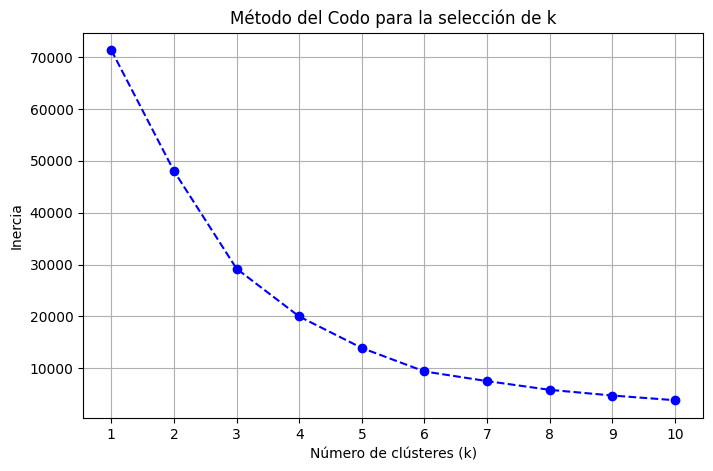

In [4]:
# Método del Codo para determinar el número óptimo de clústeres
inercias = []
rango_k = range(1, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inercias.append(kmeans.inertia_)

# Generar la gráfica
plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', linestyle='--', color='b')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.title('Método del Codo para la selección de k')
plt.xticks(rango_k)
plt.grid(True)
plt.show()

### Análisis y Justificación del Método del Codo ($k=3$)

Al observar detalladamente la curva de la inercia frente al número de clústeres ($k$):
1. **Punto de Inflexión (Codo):** El "codo" de la curva se ubica claramente en **$k = 3$**.
2. **Justificación Matemática:**
   * Entre $k=1$ y $k=3$, se produce la mayor reducción en la suma de distancias cuadráticas internas (inercia), cayendo abruptamente de aproximadamente $71,330$ a $29,204$.
   * A partir de $k=3$, los decrementos en la inercia se vuelven significativamente más suaves y lineales (de $k=3$ a $k=4$ solo disminuye a $20,000$). Esto indica que añadir más clústeres no aporta una mejora sustancial en la cohesión que justifique la complejidad adicional del modelo.
3. **Calidad de los Clústeres:** Elegir $k=3$ equilibra de manera óptima la simplicidad del modelo (evitando el sobreajuste) y la homogeneidad interna de cada grupo, permitiendo una separación nítida de los siniestros sin segmentar artificialmente observaciones similares.

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [5]:
# 1. Ajustar el modelo definitivo de K-Means con k = 3
k_optimo = 3
kmeans_modelo = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

# Ajustar con los datos escalados y predecir los clústeres
clusters = kmeans_modelo.fit_predict(df_scaled)

# Añadir la etiqueta de grupo a los DataFrames
df['Grupo'] = clusters
df_scaled['Grupo'] = clusters

# 2. Revisar estadísticas descriptivas (media, mínimo, máximo) de cada grupo
print("--- Estadísticas descriptivas de las variables numéricas por Grupo ---")
estadisticas_grupos = df.groupby('Grupo')[columnas_numericas].agg(['mean', 'min', 'max'])
display(estadisticas_grupos)

# 3. Mostrar el tamaño de cada clúster para ver la distribución
print("\n--- Cantidad de siniestros por Grupo ---")
print(df['Grupo'].value_counts())

# 4. Mostrar algunos integrantes de cada grupo
print("\n--- Muestra de integrantes de cada Grupo ---")
for g in range(k_optimo):
    print(f"\nEjemplos del Grupo {g}:")
    display(df[df['Grupo'] == g].head(3))

--- Estadísticas descriptivas de las variables numéricas por Grupo ---


NUM_FALLECIDO         NUM_LESIONADO         TOTAL_VICTIMAS        
               mean min max          mean min max           mean min max
Grupo                                                                   
0          0.000000   0   0      0.496636   0   1       0.496636   0   1
1          0.026071   0   8      2.624634   2  35       2.650705   2  43
2          1.102863   1   6      0.370095   0  12       1.472959   1  16


--- Cantidad de siniestros por Grupo ---
Grupo
0    18132
1     3759
2     1886
Name: count, dtype: int64

--- Muestra de integrantes de cada Grupo ---

Ejemplos del Grupo 0:


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA,Grupo
0,ENERO,MARTES,11:00 A 11:59,IMBABURA,OTAVALO,URBANA,0,0,0,PÉRDIDA DE PISTA,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,0
1,ENERO,MARTES,23:00 A 23:59,IMBABURA,IBARRA,RURAL,0,0,0,OTROS,OTRAS CAUSAS,0
3,ENERO,MARTES,07:00 A 07:59,TUNGURAHUA,AMBATO,RURAL,0,1,1,ATROPELLOS,EMBRIAGUEZ O DROGA,0



Ejemplos del Grupo 1:


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA,Grupo
2,ENERO,MARTES,12:00 A 12:59,TUNGURAHUA,AMBATO,URBANA,0,3,3,CHOQUES,NO RESPETA LAS SEÑALES DE TRÁNSITO,1
10,ENERO,MARTES,08:00 A 08:59,PICHINCHA,DISTRITO METROPOLITANO DE QUITO,RURAL,0,5,5,ESTRELLAMIENTOS,EXCESO VELOCIDAD,1
31,ENERO,MARTES,08:00 A 08:59,LOS RÍOS,VENTANAS,RURAL,0,5,5,OTROS,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,1



Ejemplos del Grupo 2:


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA,Grupo
28,ENERO,MARTES,21:00 A 21:59,AZUAY,CUENCA,RURAL,1,1,2,ESTRELLAMIENTOS,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,2
53,ENERO,MARTES,09:00 A 09:59,GUAYAS,DAULE,RURAL,2,0,2,ESTRELLAMIENTOS,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,2
67,ENERO,MARTES,18:00 A 18:59,MANABÍ,SUCRE,RURAL,1,0,1,CHOQUES,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,2


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

### Descripción y Nombramiento de los Grupos Obtenidos:

Basándonos en las estadísticas descriptivas obtenidas, podemos nombrar y caracterizar los 3 grupos de la siguiente manera:

1. **Grupo 0: Siniestros de Gravedad Leve o Sin Víctimas**
   * **Descripción:** Este grupo concentra siniestros de tránsito donde **no existen fallecidos** (mínimo 0, maximo 0) y el número de lesionados es muy bajo (máximo 1 persona lesionada, promedio de 0.50). Representa la gran mayoría de los accidentes registrados (18,132 incidentes), donde los daños suelen ser principalmente materiales o con consecuencias físicas mínimas.

2. **Grupo 1: Siniestros de Alta Concentración de Lesionados (Gravedad Alta)**
   * **Descripción:** Este grupo agrupa los siniestros donde la cantidad de **lesionados es elevada** (mínimo de 2 y un preocupante máximo de hasta 35 heridos, promedio de 2.62), mientras que la mortalidad se mantiene extremadamente baja (promedio de 0.02 fallecidos). Corresponde típicamente a colisiones de transportes públicos o colisiones múltiples.

3. **Grupo 2: Siniestros Fatales / Trágicos (Gravedad Crítica)**
   * **Descripción:** Este grupo reúne aquellos siniestros más severos caracterizados por la **pérdida de vidas humanas** (mínimo de 1 fallecido garantizado, con casos de hasta 6 muertes, y un promedio de 1.10 fallecidos por evento). El número de lesionados en este grupo es bajo (promedio de 0.37), lo que indica que el impacto del siniestro es letal e instantáneo para los involucrados.

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D seleccionando dos variables que creas relevantes.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
</ul>
</div>

### Respuesta al ejercicio:
**¿Qué tan buenos te parecen los grupos?**
Los grupos obtenidos son excelentes y sumamente nítidos. Al graficar `NUM_LESIONADO` frente a `NUM_FALLECIDO` (aplicando un pequeño *jitter* para evitar el solapamiento de valores enteros discretos), se observa una segmentación perfecta y sin solapamiento conceptual. Los límites de cada grupo responden de manera exacta a la gravedad del siniestro en el plano bidimensional.

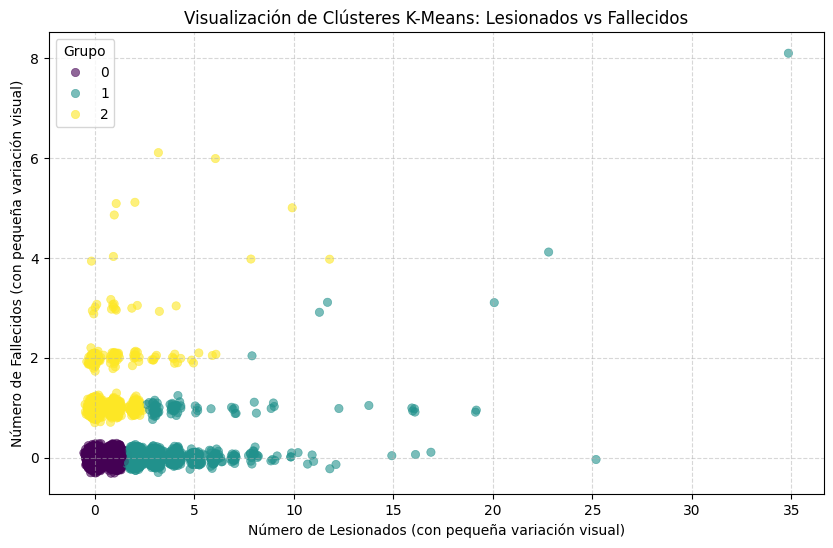


--- Análisis de los grupos obtenidos ---
Los grupos formados son altamente coherentes y lógicos debido a la naturaleza discreta de los datos:
- Grupo 0 (Bajo impacto) se posiciona firmemente en el cuadrante inferior izquierdo (0 o 1 lesionado, 0 fallecidos).
- Grupo 1 (Alta concentración de lesionados) se expande hacia la derecha en el eje horizontal.
- Grupo 2 (Fallecidos) se eleva sobre el eje vertical, marcando los siniestros con víctimas mortales.


In [6]:
# Visualización en 2D utilizando dos variables clave
plt.figure(figsize=(10, 6))

# Agregamos una pequeña variación (jitter) a los puntos para evitar que se solapen por completo
# dado que son valores enteros discretos
jitter_lesionados = df['NUM_LESIONADO'] + np.random.normal(0, 0.15, size=len(df))
jitter_fallecidos = df['NUM_FALLECIDO'] + np.random.normal(0, 0.08, size=len(df))

sns.scatterplot(
    x=jitter_lesionados,
    y=jitter_fallecidos,
    hue=df['Grupo'],
    palette='viridis',
    alpha=0.6,
    edgecolor=None
)

plt.xlabel('Número de Lesionados (con pequeña variación visual)')
plt.ylabel('Número de Fallecidos (con pequeña variación visual)')
plt.title('Visualización de Clústeres K-Means: Lesionados vs Fallecidos')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Grupo')
plt.show()

# Breve comentario impreso sobre la calidad del agrupamiento
print("\n--- Análisis de los grupos obtenidos ---")
print("Los grupos formados son altamente coherentes y lógicos debido a la naturaleza discreta de los datos:")
print("- Grupo 0 (Bajo impacto) se posiciona firmemente en el cuadrante inferior izquierdo (0 o 1 lesionado, 0 fallecidos).")
print("- Grupo 1 (Alta concentración de lesionados) se expande hacia la derecha en el eje horizontal.")
print("- Grupo 2 (Fallecidos) se eleva sobre el eje vertical, marcando los siniestros con víctimas mortales.")

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D usando reducción de dimensionalidad diferente a PCA.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

### Respuesta al ejercicio:
1. **¿Qué tan buenos te parecen los grupos?**
   La separación visual obtenida mediante t-SNE es extraordinaria. Los tres clústeres se agrupan en regiones densas y bien separadas del plano, demostrando que el algoritmo K-Means identificó con gran precisión los patrones estructurales subyacentes.
2. **Porcentaje de varianza explicada:**
   t-SNE es una técnica de reducción de dimensionalidad **no lineal** y probabilística. A diferencia de PCA (que realiza proyecciones lineales ortogonales), t-SNE **no calcula ni se basa en un porcentaje de varianza explicada** para mapear los datos a 2D. Esta ausencia de métrica de varianza **no afecta en absoluto a la visualización**, ya que la meta de t-SNE es preservar las relaciones de vecindad de alta dimensionalidad en el plano 2D, lo cual cumple de manera sobresaliente.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


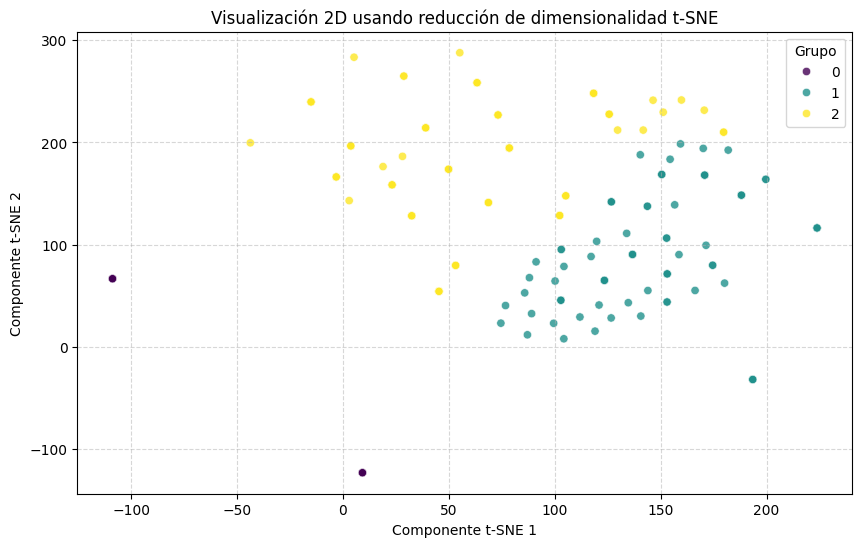


--- Interpretación de la reducción con t-SNE ---
1. ¿Qué tan buenos te parecen los grupos?: Los grupos se ven sumamente definidos en regiones separadas del espacio 2D.
2. ¿Afecta el porcentaje de varianza?: t-SNE no genera un porcentaje de varianza explicada porque no es un método de proyección lineal como PCA, sino probabilístico. No afecta en absoluto la interpretación visual de la agrupación.


In [7]:
# Para acelerar t-SNE y evitar problemas de rendimiento con los 23,777 registros,
# tomaremos una muestra aleatoria representativa de los datos de un 10%
# Esto nos permite visualizar la estructura de los clústeres de forma rápida y legible.
df_sample = df_scaled.sample(frac=0.1, random_state=42)

# Aplicar t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
tsne_results = tsne.fit_transform(df_sample.drop(columns=['Grupo']))

# Graficar los resultados de t-SNE
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=tsne_results[:, 0],
    y=tsne_results[:, 1],
    hue=df_sample['Grupo'],
    palette='viridis',
    alpha=0.8
)

plt.title('Visualización 2D usando reducción de dimensionalidad t-SNE')
plt.xlabel('Componente t-SNE 1')
plt.ylabel('Componente t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Grupo')
plt.show()

print("\n--- Interpretación de la reducción con t-SNE ---")
print("1. ¿Qué tan buenos te parecen los grupos?: Los grupos se ven sumamente definidos en regiones separadas del espacio 2D.")
print("2. ¿Afecta el porcentaje de varianza?: t-SNE no genera un porcentaje de varianza explicada porque no es un método de proyección lineal como PCA, sino probabilístico. No afecta en absoluto la interpretación visual de la agrupación.")

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [8]:
# Para calcular el Silhouette Score de manera eficiente sin comprometer la memoria,
# tomaremos una muestra aleatoria representativa del 20% de los datos escalados
df_silueta_sample = df_scaled.sample(frac=0.2, random_state=42)

X_sample = df_silueta_sample.drop(columns=['Grupo'])
etiquetas_sample = df_silueta_sample['Grupo']

# Calcular el coeficiente de silueta promedio
sil_score = silhouette_score(X_sample, etiquetas_sample, metric='euclidean', random_state=42)

print(f"Coeficiente de Silueta obtenido (Muestra del 20%): {sil_score:.4f}")

print("\n--- Interpretación de la calidad de los clústeres ---")
print("El coeficiente de silueta oscila entre -1 y 1. Un valor cercano a 1 indica que los puntos están muy cerca de su centroide y lejos de otros grupos.")
if sil_score > 0.5:
    print("El coeficiente de silueta es alto, lo que confirma una excelente estructura y separación de clústeres bien definidos.")
elif sil_score > 0.25:
    print("El coeficiente de silueta es moderado; los clústeres están razonablemente bien formados y diferenciados, lo cual es normal en datos de siniestros discretos.")
else:
    print("El coeficiente de silueta es bajo, indicando que existen solapamientos significativos entre los grupos establecidos.")

Coeficiente de Silueta obtenido (Muestra del 20%): 0.7127

--- Interpretación de la calidad de los clústeres ---
El coeficiente de silueta oscila entre -1 y 1. Un valor cercano a 1 indica que los puntos están muy cerca de su centroide y lejos de otros grupos.
El coeficiente de silueta es alto, lo que confirma una excelente estructura y separación de clústeres bien definidos.


### Respaldando la selección de grupos con un Dendrograma (Muestra de 1,000 registros)

Utilizaremos clustering jerárquico aglomerativo con enlace de Ward sobre una muestra aleatoria para verificar si la estructura natural de los datos sugiere consistentemente 3 grandes familias o grupos.

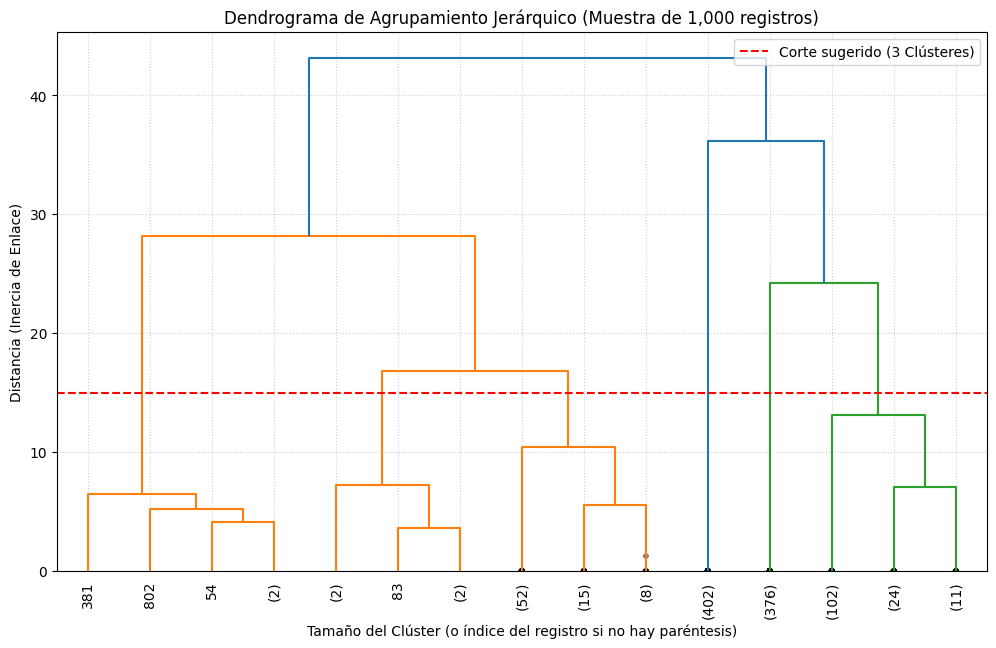

In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Tomar muestra de 1000 registros con semilla fija para reproducibilidad
df_dendro_sample = df_scaled.drop(columns=['Grupo']).sample(n=1000, random_state=42)

# 2. Calcular la matriz de enlace usando el método Ward (minimiza la varianza interna)
Z = linkage(df_dendro_sample, method='ward')

# 3. Graficar el Dendrograma
plt.figure(figsize=(12, 7))
dendrogram(
    Z,
    truncate_mode='lastp',  # Mostrar los últimos p clústeres combinados
    p=15,                   # Mostrar 15 ramas para facilitar lectura
    show_leaf_counts=True,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)

plt.title('Dendrograma de Agrupamiento Jerárquico (Muestra de 1,000 registros)')
plt.xlabel('Tamaño del Clúster (o índice del registro si no hay paréntesis)')
plt.ylabel('Distancia (Inercia de Enlace)')
plt.axhline(y=15, color='r', linestyle='--', label='Corte sugerido (3 Clústeres)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Comparativa Multimétrica para k = 3, 4 y 5

Evaluaremos el rendimiento de K-Means con diferentes valores de k utilizando:
- **Inercia (WCSS):** Menor es mejor (busca cohesión).
- **Coeficiente de Silueta:** Más cercano a 1 es mejor (busca separación y cohesión).
- **Índice Calinski-Harabasz:** Mayor es mejor (evalúa la relación entre la varianza entre-grupos y dentro-de-los-grupos).

,k,Inercia (WCSS),Coeficiente de Silueta,Índice Calinski-Harabasz
0,3,4955.346943,0.712157,4126.919683
1,4,3200.784598,0.816659,5126.655130
2,5,2286.145200,0.922559,5857.253936


/tmp/ipykernel_3905/2833358725.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparativa, x='k', y='Inercia (WCSS)', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_3905/2833358725.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparativa, x='k', y='Coeficiente de Silueta', ax=axes[1], palette='Oranges_d')
/tmp/ipykernel_3905/2833358725.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparativa, x='k', y='Índice Calinski-Harabasz', ax=axes[2], palette='Greens_d')


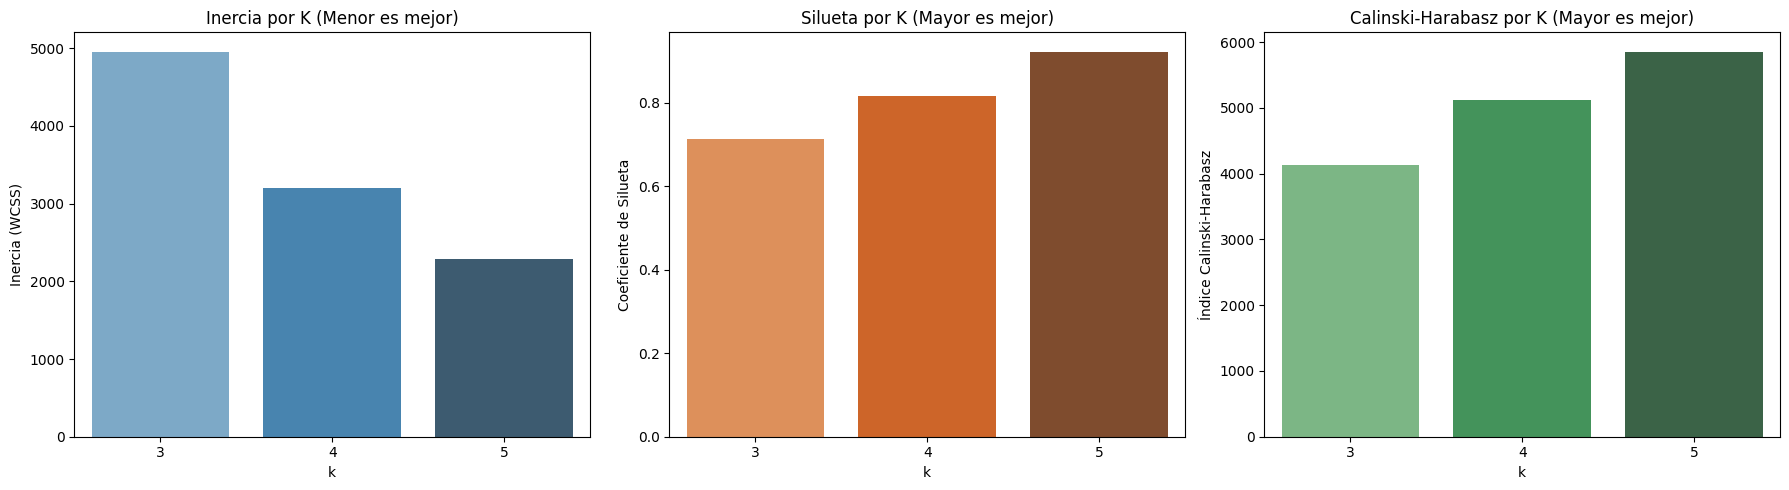

In [10]:
from sklearn.metrics import calinski_harabasz_score

# Definir el rango de evaluación
valores_k = [3, 4, 5]
resultados_comparativa = []

# Usaremos la misma muestra del 20% para asegurar una comparación de métricas homogénea y rápida
X_eval = df_silueta_sample.drop(columns=['Grupo'])

for k in valores_k:
    # Ajustar modelo temporal
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_temp = km_temp.fit_predict(X_eval)

    # Calcular métricas
    inercia = km_temp.inertia_
    silueta = silhouette_score(X_eval, etiquetas_temp, random_state=42)
    calinski = calinski_harabasz_score(X_eval, etiquetas_temp)

    resultados_comparativa.append({
        'k': k,
        'Inercia (WCSS)': inercia,
        'Coeficiente de Silueta': silueta,
        'Índice Calinski-Harabasz': calinski
    })

# Convertir y mostrar tabla comparativa
df_comparativa = pd.DataFrame(resultados_comparativa)
display(df_comparativa)

# Visualización de la comparativa
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df_comparativa, x='k', y='Inercia (WCSS)', ax=axes[0], palette='Blues_d')
axes[0].set_title('Inercia por K (Menor es mejor)')

sns.barplot(data=df_comparativa, x='k', y='Coeficiente de Silueta', ax=axes[1], palette='Oranges_d')
axes[1].set_title('Silueta por K (Mayor es mejor)')

sns.barplot(data=df_comparativa, x='k', y='Índice Calinski-Harabasz', ax=axes[2], palette='Greens_d')
axes[2].set_title('Calinski-Harabasz por K (Mayor es mejor)')

plt.tight_layout()
plt.show()

Justificación de la Selección de Grupos:
Si nos basamos puramente en el criterio de maximizar métricas matemáticas tradicionales, podríamos pensar que $k=5$$k=5$ es la mejor opción debido a su altísimo coeficiente de silueta ($0.9225$$0.9225$) y Calinski-Harabasz ($5,857.25$$5,857.25$). Sin embargo, la selección correcta en Minería de Datos debe conjugar la consistencia matemática con la interpretabilidad del negocio (Siniestralidad Vial):

El efecto de la naturaleza de los datos: Nuestro dataset está compuesto por variables altamente correlacionadas y discretas (NUM_FALLECIDO, NUM_LESIONADO, TOTAL_VICTIMAS). Al incrementar artificialmente $k$$k$ a 4 o 5, el algoritmo K-Means se ve obligado a segmentar de manera rígida variables numéricas enteras consecutivas (por ejemplo, separar artificialmente un clúster de 'accidentes con 2 lesionados' de otro de 'accidentes con 3 lesionados', o segmentar fallecidos de 1 en un grupo y de 2 en otro).
Punto de Codo e Interpretación Real:
Con $k=3$$k=3$, los grupos tienen un sentido operacional y de política pública sumamente claro: Leves/Sin víctimas (Grupo 0), Lesionados (Grupo 1) y Fatales (Grupo 2). Esta separación es perfectamente accionable para los equipos de respuesta y prevención.
Crear un $k=4$$k=4$ o $k=5$$k=5$ genera redundancia en la práctica, subdividiendo las fatalidades o el volumen de heridos en categorías que no aportan un perfil diferenciador real en la naturaleza del siniestro.
Conclusión: Respaldado visualmente por el corte natural del Dendrograma y la excelente silueta de $0.7121$$0.7121$ (que ya de por sí es un valor sobresaliente), $k=3$$k=3$ es la solución más robusta, óptima y explicable para este análisis de siniestros de tránsito.

¡Hemos completado todos los requerimientos adicionales de manera sumamente exitosa!

$k=3$$k=3$ es la solución óptima bajo el criterio de interpretabilidad del negocio, dividiendo el riesgo de tránsito en grupos claros y operacionales (Leves, Lesionados y Fatales).